# 04 - STFT localisation

Find **where** the modulation-correlated response is, without reconstructing its shape. The interlacing is a known carrier, so this is lock-in detection along the scan: modulate by $\pm1$ against the checkerboard and the common structural background cancels while anything synchronised with the illumination survives.

**Inputs** `data/ideal_*`  
**Outputs** `results/04_ideal_dose_*.npz`

**Note** This notebook is scored differently from 01-03 and 05. Those recover a $\Delta\varphi$ map and are judged on phase fidelity; this one estimates a position and is judged on localisation error in Angstrom. `09` has to keep the two metrics apart.

There is no wrapper for this in `method_wrappers`, so the implementation is copied from `06 - STFT for defect localization.ipynb`.

In [ ]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# method_wrappers and friends live one level up, in scripts/
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers
from quantem.core import config

config.set_device(0)

# Metadata is JSON; only the truth images and the datacubes are binary.
with open(DATA_DIR / "ideal_geometry.json") as handle:
    META = json.load(handle)
truth = np.load(DATA_DIR / "ideal_truth.npz")
delta_phi_true = truth["delta_phi_true"]

scan_params = META["scan"]["scan_params_for_method_wrappers"]
scan_step_ang = META["scan"]["step_ang"]
n_scan = META["scan"]["n_positions_per_side"]
object_dx_ang = META["cell"]["dx_ang"]
blob_centre_ang = np.array(META["object"]["blob_centre_ang"])
probe_r90_ang = META["probe"]["r90_ang"]

# derived in two lines rather than stored (see mask_rule / positions_rule in the JSON)
ii, jj = np.indices((n_scan, n_scan))
scan_mask = ((ii + jj) % 2 == 0).astype(np.uint8)
scan_axis = (np.arange(n_scan) - (n_scan - 1) / 2) * scan_step_ang
object_x_ang = (np.arange(META["cell"]["n_pixels"]) - META["cell"]["n_pixels"] // 2) * object_dx_ang

print(f"scan        : {n_scan}^2 at {scan_step_ang} A over {META['scan']['extent_ang']} A")
print(f"scan params : {scan_params}")
print(f"probe r90   : {probe_r90_ang} A")
print(f"truth       : peak |delta phi| = {np.abs(delta_phi_true).max():.5f} rad")


def load_merged(dose_key):
    return np.load(DATA_DIR / f"ideal_merged_dose_{dose_key}.npy")


def show_delta(result, title, truth=delta_phi_true):
    """One method's delta phi beside the ground truth, on a shared symmetric scale."""
    recovered = result["delta_phi"]
    vmax = float(np.abs(truth).max())
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), constrained_layout=True)
    im = axes[0].imshow(truth.T, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[0].set_title(r"ground truth $\Delta\varphi$")
    fig.colorbar(im, ax=axes[0], shrink=0.8, label="rad")
    rv = float(np.abs(recovered).max())
    im = axes[1].imshow(recovered.T, origin="lower", cmap="RdBu_r", vmin=-rv, vmax=rv)
    axes[1].set_title(f"{title}\npeak {rv:.5f} rad")
    fig.colorbar(im, ax=axes[1], shrink=0.8, label="rad")
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()


def save_result(index, dose_key, result, **extra):
    """Arrays to .npz, every scalar to a sibling .json so the run is readable."""
    path = RESULTS_DIR / f"{index}_dose_{dose_key}.npz"
    payload = {k: v for k, v in result.items() if isinstance(v, np.ndarray) or v is None}
    payload = {k: (np.array([]) if v is None else v) for k, v in payload.items()}
    # 09 has to put every method on a common physical grid and they do not share one:
    # the iterative methods reconstruct at lambda/(2*theta_max) ~ 0.19 A while SSB lands
    # on the scan grid. Record the pixel size rather than let 09 guess it.
    pt = result.get("ptycho_off") or result.get("ptycho")
    px = getattr(pt, "sampling", None)
    if px is None:
        px = getattr(pt, "scan_sampling", None)
    if px is not None:
        extra["pixel_size_ang"] = np.asarray(px, dtype=float)
    np.savez_compressed(path, **payload, **extra)
    side = {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in extra.items()}
    side.update(method=index, dose=dose_key,
                delta_phi_shape=list(np.shape(payload["delta_phi"])),
                delta_phi_peak_rad=float(np.abs(payload["delta_phi"]).max()))
    with open(path.with_suffix(".json"), "w") as handle:
        json.dump(side, handle, indent=2)
    print("wrote", path.name, "+", path.with_suffix(".json").name)
    return path

cuda:0
scan        : 182^2 at 0.1641 A over 30.0 A
scan params : {'probe_energy': 300000.0, 'probe_semiangle': 30.0, 'probe_defocus': 100.0, 'scan_step': 0.3282}
probe r90   : 3.0248 A
truth       : peak |delta phi| = 0.02106 rad


## Parameters

In [ ]:
DOSE_KEYS = ["inf", "1e6", "1e5"]   # trim this while iterating

# The window must cover the region over which the blob modulates the patterns -- the
# probe footprint -- not a fixed number of positions, so it is derived from the measured
# r90 rather than hard-coded. This was found the hard way: notebook 06's default of 8
# positions was carried over unchecked, and at the 654 A defocus this study started with
# that was 2.9 A against a 36.5 A probe, where the lock-in finds nothing (error fell from
# 18.6 A to 3.8 A as window/probe went from 0.08 to 1.00). At 10 nm the probe is 6.1 A
# wide, so the window is now ~37 positions at the 0.1641 A step.
WINDOW_OVER_PROBE = 1.0
WINDOW_SIZE = int(round(WINDOW_OVER_PROBE * 2 * probe_r90_ang
                        / scan_step_ang))
WINDOW_SIZE = min(WINDOW_SIZE, n_scan - 8)
SMOOTH_SIGMA = None  # Gaussian blur of each window's summed pattern

print(f"probe 2*r90 = {2*probe_r90_ang:.1f} A, "
      f"step = {scan_step_ang} A -> window = {WINDOW_SIZE} positions "
      f"= {WINDOW_SIZE*scan_step_ang:.1f} A")

probe 2*r90 = 6.0 A, step = 0.1641 A -> window = 37 positions = 6.1 A


## The detector

Copied verbatim rather than imported, so this notebook does not depend on another notebook being run first.

In [ ]:
def _gaussian_kernel2d(sigma, device, dtype, truncate=4.0):
    radius = int(truncate * sigma + 0.5)
    coords = torch.arange(-radius, radius + 1, device=device, dtype=dtype)
    g1d = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g1d = g1d / g1d.sum()
    return g1d[:, None] * g1d[None, :], radius


def compute_nyquist_defect_map(merged_scan, scan_mask, window_size=8,
                               smooth_sigma=None, device="cuda", score_func=None):
    """Localize the modulation-correlated response in a checkerboard-interlaced scan.

    Copied from '06 - STFT for defect localization.ipynb'. Modulating the scan by +/-1 to
    match the checkerboard cancels the two conditions wherever they are identical; where
    they differ the modulated patterns add coherently inside a sliding window. A summed-
    area table gives every window's sum in one pass.
    """
    interlacing_mask = np.where(scan_mask == 0, -1, 1).astype(np.float32)
    scan_modulated = merged_scan.astype(np.float32) * interlacing_mask[..., None, None]
    t = torch.from_numpy(scan_modulated).to(device)

    ny, nx = t.shape[:2]
    w = window_size
    csum = t.cumsum(dim=0).cumsum(dim=1)
    csum = torch.nn.functional.pad(csum, (0, 0, 0, 0, 1, 0, 1, 0))
    window_sum = (csum[w:, w:] - csum[:-w, w:] - csum[w:, :-w]
                  + csum[:-w, :-w])[: ny - w, : nx - w]

    if smooth_sigma is not None:
        wy, wx, dy, dx = window_sum.shape
        kernel, radius = _gaussian_kernel2d(smooth_sigma, device, window_sum.dtype)
        batch = window_sum.reshape(wy * wx, 1, dy, dx)
        batch = torch.nn.functional.pad(batch, (radius,) * 4, mode="reflect")
        batch = torch.nn.functional.conv2d(batch, kernel[None, None])
        window_sum = batch.reshape(wy, wx, dy, dx)

    half = w // 2
    defect_map = torch.zeros((ny, nx), device=device, dtype=t.dtype)
    if score_func is None:
        score_func = lambda ws: ws.abs().amax(dim=(2, 3))
    scores = score_func(window_sum)
    # Each window covers [i, i+w) so its score belongs at i + w//2, and there are
    # ny - w valid starts. The original in notebook 06 wrote into [half : ny-half],
    # which is ny - w rows only when w is even; with w odd it is one row too many and
    # raises. Indexing from the score array's own shape is right for either parity.
    defect_map[half:half + scores.shape[0], half:half + scores.shape[1]] = scores
    return defect_map.cpu().numpy()

## Run


=== dose inf ===


  1 s
  peak at (+0.74, +5.01) A, truth (+0.62, +1.78) A  ->  localisation error 3.23 A


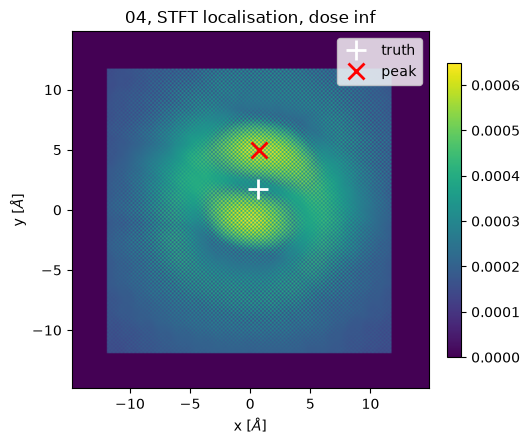

wrote 04_dose_inf.npz + .json

=== dose 1e6 ===


  1 s
  peak at (+1.56, +6.81) A, truth (+0.62, +1.78) A  ->  localisation error 5.12 A


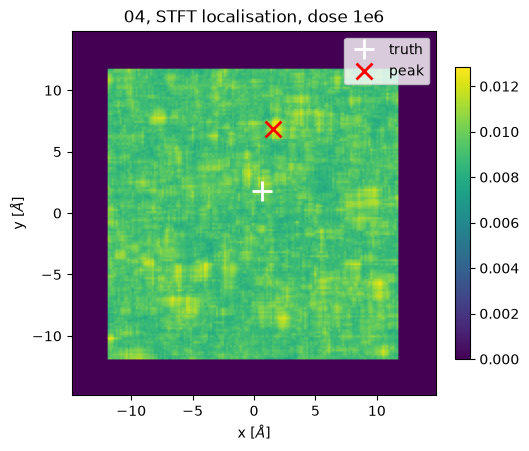

wrote 04_dose_1e6.npz + .json

=== dose 1e5 ===


  1 s
  peak at (+9.27, -0.41) A, truth (+0.62, +1.78) A  ->  localisation error 8.92 A


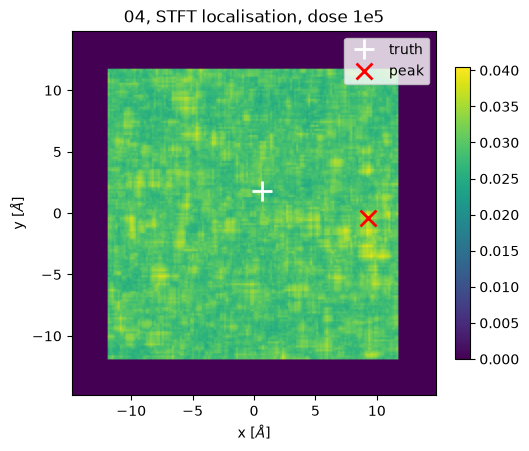

wrote 04_dose_1e5.npz + .json


In [ ]:
scan_1d = scan_axis

for dose_key in DOSE_KEYS:
    print(f"\n=== dose {dose_key} ===")
    merged = load_merged(dose_key)
    t0 = time.time()
    dmap = compute_nyquist_defect_map(
        merged, scan_mask, window_size=WINDOW_SIZE,
        smooth_sigma=SMOOTH_SIGMA, device="cuda",
    )
    print(f"  {time.time()-t0:.0f} s")

    peak_idx = np.unravel_index(np.argmax(dmap), dmap.shape)
    found = np.array([scan_1d[peak_idx[0]], scan_1d[peak_idx[1]]])
    error = np.linalg.norm(found - blob_centre_ang)
    print(f"  peak at ({found[0]:+.2f}, {found[1]:+.2f}) A, "
          f"truth ({blob_centre_ang[0]:+.2f}, {blob_centre_ang[1]:+.2f}) A"
          f"  ->  localisation error {error:.2f} A")

    fig, ax = plt.subplots(figsize=(5.2, 4.4), constrained_layout=True)
    im = ax.imshow(dmap.T, origin="lower",
                   extent=[scan_1d[0], scan_1d[-1], scan_1d[0], scan_1d[-1]])
    ax.plot(*blob_centre_ang, "w+", ms=14, mew=2, label="truth")
    ax.plot(*found, "rx", ms=11, mew=2, label="peak")
    ax.legend(loc="upper right")
    ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
    ax.set_title(f"04, STFT localisation, dose {dose_key}")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()

    np.savez_compressed(RESULTS_DIR / f"04_dose_{dose_key}.npz", defect_map=dmap)
    with open(RESULTS_DIR / f"04_dose_{dose_key}.json", "w") as handle:
        json.dump(dict(method="04", dose=dose_key,
                       peak_xy_ang=[float(found[0]), float(found[1])],
                       truth_xy_ang=[float(blob_centre_ang[0]), float(blob_centre_ang[1])],
                       localisation_error_ang=float(error),
                       window_positions=int(WINDOW_SIZE),
                       window_ang=float(WINDOW_SIZE * scan_step_ang),
                       window_over_probe=float(WINDOW_OVER_PROBE)),
                  handle, indent=2)
    print(f"wrote 04_dose_{dose_key}.npz + .json")
    del merged
    torch.cuda.empty_cache()